In [1]:
import os
os.environ['PATH'] = "/home/nrui/.local/texlive/2025/bin/x86_64-linux:" + os.environ['PATH']

from matplotlib import pyplot as plt
import numpy as np

import matplotlib 
fig_width_pt = 3*246.0                  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inch
golden_mean = (np.sqrt(5)-1.0)/2.0      # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean      # height in inches
fig_size =  [fig_width,fig_height]
params = {'axes.labelsize': 24,
          'font.family': 'serif',
          'font.serif': 'Computer Modern',
          'font.size': 24,
          'legend.fontsize': 20,
          'xtick.labelsize': 18,
          'ytick.labelsize': 18,
          'axes.grid' : False,
          'text.usetex': True,
          'savefig.dpi' : 100,
          'lines.markersize' : 14,
          'figure.figsize': fig_size}
matplotlib.rcParams.update(params)


In [2]:
def dedup(a):
    # the duration sweep contains a few repeated points (same freq_length);
    # keep only the first measurement of each x
    _, idx = np.unique(a[:, 0], return_index=True)
    return a[np.sort(idx)]


# waveform
ti_wf_cpu = dedup(np.loadtxt("perf_ti_wf_x64_f64.dat"))
# display(ti_wf_cpu)

ti_wf_cuda = dedup(np.loadtxt("perf_ti_wf_cuda_f64.dat"))
# display(ti_wf_cuda)

jax_wf_cpu = dedup(np.loadtxt("perf_jax_wf_cpu_f64.dat"))
# display(jax_wf_cpu)

jax_wf_gpu = dedup(np.loadtxt("perf_jax_wf_gpu_f64.dat"))
# display(jax_wf_gpu)

lal_wf = dedup(np.loadtxt("perf_wf_lal.dat"))
# display(lal_wf)

# likelihood
ti_ll_cpu = dedup(np.loadtxt("perf_ti_ll_x64_f64.dat"))
# display(ti_ll_cpu)

ti_ll_cuda = dedup(np.loadtxt("perf_ti_ll_cuda_f64.dat"))
# display(ti_ll_cuda)

jax_ll_cpu = dedup(np.loadtxt("perf_jax_ll_cpu_f64.dat"))
# display(jax_ll_cpu)

jax_ll_gpu = dedup(np.loadtxt("perf_jax_ll_gpu_f64.dat"))
# display(jax_ll_gpu)

bbhx_ll_cpu = dedup(np.loadtxt("perf_bbhx_ll_cpu.dat"))
# display(bbhx_ll_cpu)

bbhx_ll_cuda = dedup(np.loadtxt("perf_bbhx_ll_cuda.dat"))
# display(bbhx_ll_cuda)

In [3]:
DAYJUL_SI = 86400.0
dt = 10
f_min = 1e-4
f_max = 0.5 * (1 / dt)

duration = {'week': 7*DAYJUL_SI, 'month': 30*DAYJUL_SI, 'year':365*DAYJUL_SI}
freq_num = {}
for key, value in duration.items():
    full_freqs = np.fft.rfftfreq(int(value/dt), dt)
    freqs = full_freqs[(full_freqs >= f_min) * (full_freqs <= f_max)]
    freq_num[key] = len(freqs)
freq_num

{'week': 30180, 'month': 129341, 'year': 1573647}

In [4]:
tab20_colors = plt.cm.tab20.colors

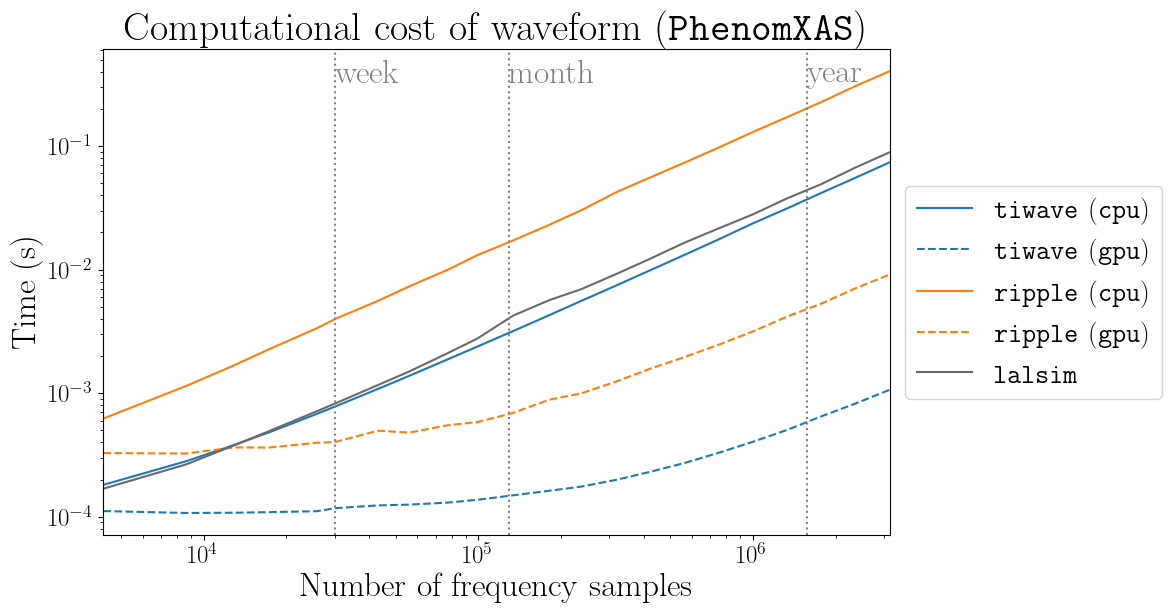

In [5]:
# waveform
plt.figure(figsize=(fig_size[0] + 4.2, fig_size[1]))
plt.gca().set_box_aspect(golden_mean)
plt.loglog(ti_wf_cpu[:,0], ti_wf_cpu[:,1], label=r"\texttt{tiwave} (\texttt{cpu})", color=tab20_colors[0])
plt.loglog(ti_wf_cuda[:,0], ti_wf_cuda[:,1], label=r"\texttt{tiwave} (\texttt{gpu})", color=tab20_colors[0], linestyle='dashed')
plt.loglog(jax_wf_cpu[:,0], jax_wf_cpu[:,1], label=r"\texttt{ripple} (\texttt{cpu})", color=tab20_colors[2])
plt.loglog(jax_wf_gpu[:,0], jax_wf_gpu[:,1], label=r"\texttt{ripple} (\texttt{gpu})", color=tab20_colors[2], linestyle='dashed')

plt.loglog(lal_wf[:,0], lal_wf[:,1], label=r"\texttt{lalsim}", color="dimgray")

for key, value in freq_num.items():
    plt.axvline(value, color='gray', linestyle='dotted')
    plt.text(value, 0.98, key, color='gray', ha='left', va='top',
             transform=plt.gca().get_xaxis_transform())

plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
plt.xlim(ti_wf_cpu[0,0], ti_wf_cpu[-1,0])
plt.xlabel("Number of frequency samples")
plt.ylabel("Time (s)")
plt.title(r"Computational cost of waveform ($\texttt{PhenomXAS}$)")
plt.savefig("perf_wf.pdf", bbox_inches="tight")

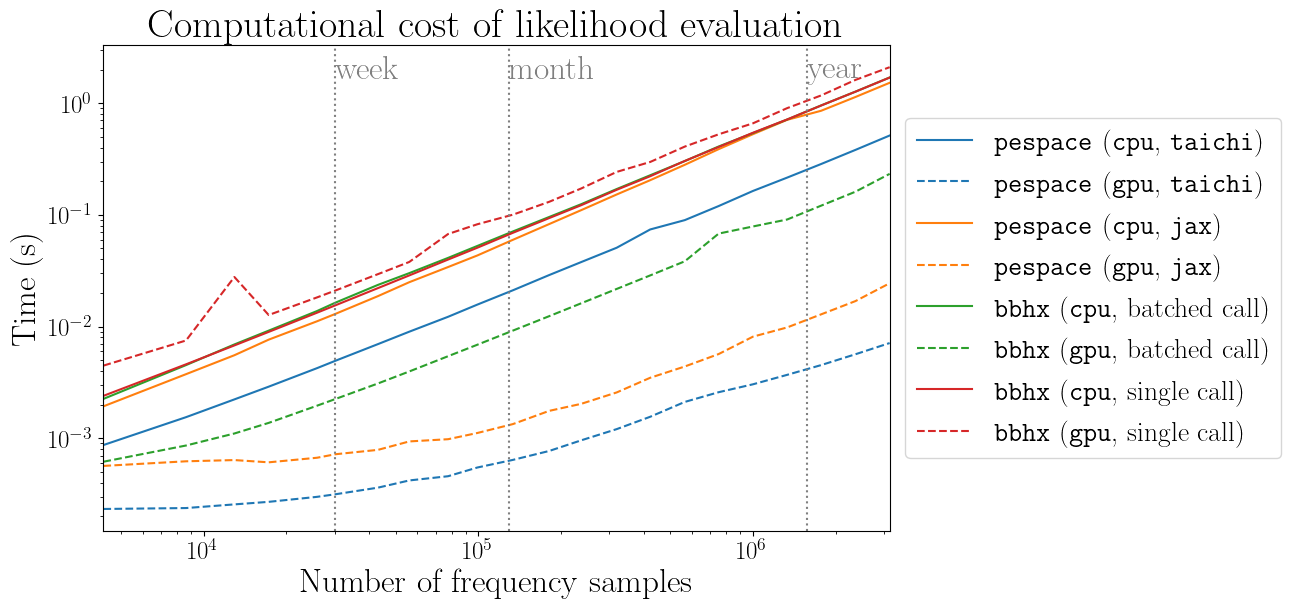

In [10]:
# likelihood
plt.figure(figsize=(fig_size[0] + 6.2, fig_size[1]))
plt.gca().set_box_aspect(golden_mean)
plt.loglog(ti_ll_cpu[:,0], ti_ll_cpu[:,1], label=r"\texttt{pespace} (\texttt{cpu}, \texttt{taichi})", color=tab20_colors[0])
plt.loglog(ti_ll_cuda[:,0], ti_ll_cuda[:,1], label=r"\texttt{pespace} (\texttt{gpu}, \texttt{taichi})", color=tab20_colors[0], linestyle='dashed')

plt.loglog(jax_ll_cpu[:,0], jax_ll_cpu[:,1], label=r"\texttt{pespace} (\texttt{cpu}, \texttt{jax})", color=tab20_colors[2])
plt.loglog(jax_ll_gpu[:,0], jax_ll_gpu[:,1], label=r"\texttt{pespace} (\texttt{gpu}, \texttt{jax})", color=tab20_colors[2], linestyle='dashed')

plt.loglog(bbhx_ll_cpu[:,0], bbhx_ll_cpu[:,2], label=r"\texttt{bbhx} (\texttt{cpu}, batched call)", color=tab20_colors[4])
plt.loglog(bbhx_ll_cuda[:,0], bbhx_ll_cuda[:,2], label=r"\texttt{bbhx} (\texttt{gpu}, batched call)", color=tab20_colors[4], linestyle='dashed')

plt.loglog(bbhx_ll_cpu[:,0], bbhx_ll_cpu[:,1], label=r"\texttt{bbhx} (\texttt{cpu}, single call)", color=tab20_colors[6])
plt.loglog(bbhx_ll_cuda[:,0], bbhx_ll_cuda[:,1], label=r"\texttt{bbhx} (\texttt{gpu}, single call)", color=tab20_colors[6], linestyle='dashed')


for key, value in freq_num.items():
    plt.axvline(value, color='gray', linestyle='dotted')
    plt.text(value, 0.98, key, color='gray', ha='left', va='top',
             transform=plt.gca().get_xaxis_transform())

plt.xlim(ti_ll_cpu[0,0], ti_ll_cpu[-1,0])
plt.xlabel("Number of frequency samples")
plt.ylabel("Time (s)")
plt.title("Computational cost of likelihood evaluation")
plt.subplots_adjust(right=0.62)
plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
plt.savefig("perf_ll.pdf", bbox_inches="tight")